# Chapter 11 Lab — Cycle Analysis

**Purpose:** replicate and understand the main Chapter 11 ideas, and learn how easily cycles can be *invented* by the analysis itself.

This notebook is deliberately **not** an optimisation exercise and **not** a production backtest.
It uses synthetic data where the true answer is known, the book's own copper table, and the NIFTY monthly data already in this repository.

## Learning objectives

By the end of this notebook you should be able to:
1. describe a cycle by amplitude, period, frequency and phase;
2. remove a trend before looking for a cycle;
3. build a triangular-weighted MACD;
4. fit a single-frequency trigonometric regression (the book's copper example);
5. read a periodogram and recover known cycles from synthetic data;
6. show how smoothing **creates** cycles in pure noise (the most important failure mode);
7. test for a cycle against a pre-declared null instead of eyeballing peaks;
8. calculate the Hilbert-transform phase, the Fisher transform, the inverse Fisher transform and the CCI;
9. explain why Hurst's phased moving averages look ahead.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
REPO = HERE.parents[1]
rng = np.random.default_rng(11)

## 1. Describing a cycle

`y = a · sin(ωφ + b)`

- **amplitude** `a`: height from the midpoint;
- **period** `T`: bars per full cycle;
- **frequency** `ω = 1/T` (or 360°/T in degrees per bar);
- **phase** `b`: where in the cycle the series starts.

Real prices are never one wave. The book's compound wave (Figure 11.8) adds two:
`y = 3 sin 4φ + 6 sin 5φ`.

**Book typo:** the text on p. 498 writes `y₂ = 5 sin 6φ`, but the figure label and the derivative on p. 499 both use `y₂ = 6 sin 5φ`. The code uses `6 sin 5φ`.

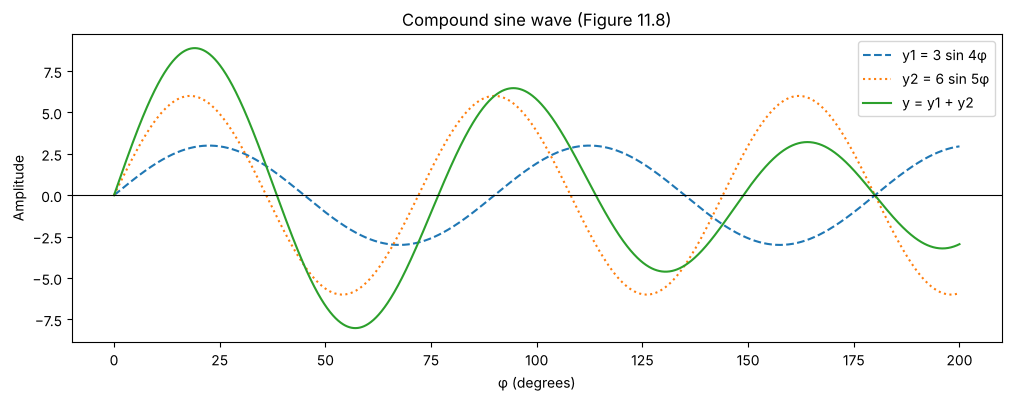

Extremes match the book: y1 max 22.5°, min 67.5°; y2 max 18°, min 54°.
Compound wave range: -8.03 to 8.89 (never reaches ±9, because the peaks do not line up).


In [2]:
phi = np.linspace(0, 200, 2001)          # degrees
rad = np.radians
y1 = 3 * np.sin(rad(4 * phi))
y2 = 6 * np.sin(rad(5 * phi))
y = y1 + y2

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(phi, y1, '--', label='y1 = 3 sin 4φ')
ax.plot(phi, y2, ':', label='y2 = 6 sin 5φ')
ax.plot(phi, y, label='y = y1 + y2')
ax.axhline(0, linewidth=0.8, color='black')
ax.set(title='Compound sine wave (Figure 11.8)', xlabel='φ (degrees)', ylabel='Amplitude')
ax.legend()
plt.show()

# The book: y1' = 0 where 4φ = 90°, 270° -> φ = 22.5° (max) and 67.5° (min);
#           y2' = 0 where 5φ = 90°, 270° -> φ = 18° (max) and 54° (min).
for name, wave, mx, mn in [('y1', y1, 22.5, 67.5), ('y2', y2, 18, 54)]:
    first = phi <= 90
    assert np.isclose(phi[first][np.argmax(wave[first])], mx)
    assert np.isclose(phi[first][np.argmin(wave[first])], mn)
print('Extremes match the book: y1 max 22.5°, min 67.5°; y2 max 18°, min 54°.')
print(f'Compound wave range: {y.min():.2f} to {y.max():.2f} (never reaches ±9, because the peaks do not line up).')

## 2. Synthetic test series: trend + cycle + noise

Before using any cycle tool on real prices, check that it recovers a cycle **we planted ourselves**.

`price = trend + 2·sin(2πt/40) + 1·sin(2πt/20) + noise`

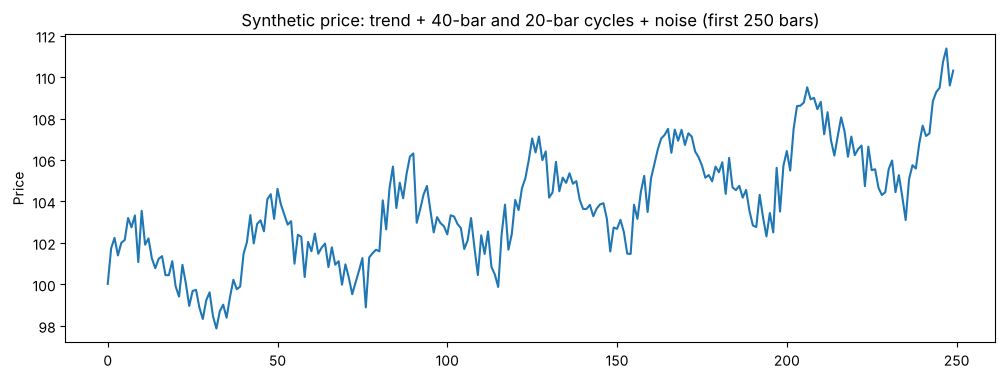

In [3]:
n = 750
t = np.arange(n)
TRUE_PERIODS = (40, 20)
synthetic = pd.Series(
    100 + 0.03 * t
    + 2.0 * np.sin(2 * np.pi * t / TRUE_PERIODS[0])
    + 1.0 * np.sin(2 * np.pi * t / TRUE_PERIODS[1])
    + rng.normal(0, 0.8, n),
    index=pd.RangeIndex(n, name='bar'), name='price')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(synthetic.iloc[:250])
ax.set(title='Synthetic price: trend + 40-bar and 20-bar cycles + noise (first 250 bars)', ylabel='Price')
plt.show()

## 3. Removing the trend

A trend dominates everything else, so it must go first. The book gives several ways:

| Method | Formula | Note |
|---|---|---|
| Moving-average residual | `P_t − MA_n(P)_t` | `n` near the cycle you expect |
| n-bar difference | `P_t − P_{t−n}` | removes cycles of length `n` |
| Two-EMA MACD | `EMA_short − EMA_long` | long = ½ dominant cycle, short = ½ long |
| Least-squares line | `P_t − (a + b·t)` | used for the copper example |
| **Triangular MACD** | `TMA_P − TMA_{P/2}` | smoother version of the MACD idea |

### Triangular weighting (p. 495)

Weights rise in equal steps of `2/(P/2)` to **2.0** at the centre, then fall. For `P = 10`: 0.4, 0.8, 1.2, 1.6, 2.0, 1.6, 1.2, 0.8, 0.4. That is nine prices, because an even period has to drop the oldest one to have a centre.

**Book typo:** the TMA formula on p. 495 is printed with `×` between the terms. They are **added**:
`TMA_t = (w₁P_{t−P+2} + w₂P_{t−P+3} + … + w_{P−1}P_t) / P`.

P=10 weights: [0.4 0.8 1.2 1.6 2.  1.6 1.2 0.8 0.4]


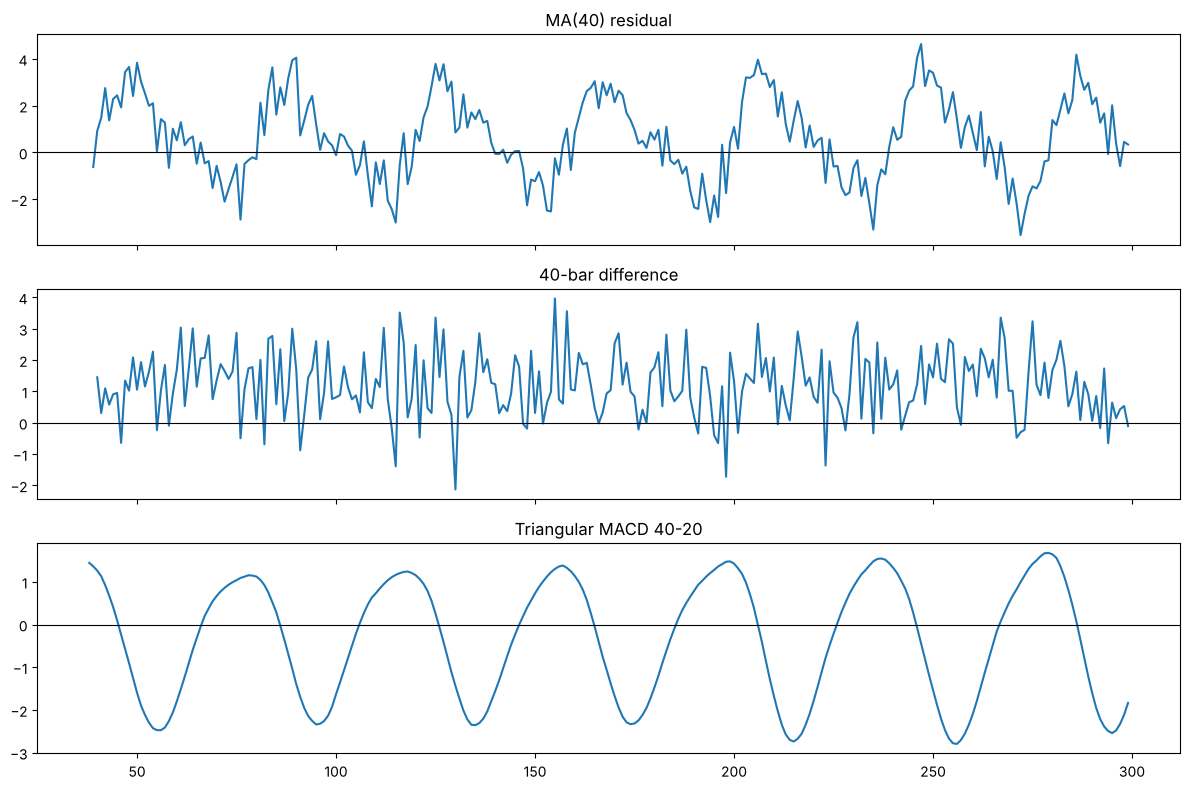

Note: the 40-bar difference removes the 40-bar cycle completely, leaving mostly the 20-bar cycle.


In [4]:
def triangular_weights(period):
    half = period // 2
    up = np.arange(1, half + 1) * (2.0 / half)
    return np.concatenate([up, up[-2::-1]])

def tma(series, period):
    w = triangular_weights(period)
    return series.rolling(len(w)).apply(lambda x: np.dot(x, w) / w.sum(), raw=True)

def triangular_macd(series, period):
    return tma(series, period) - tma(series, period // 2)

w10 = triangular_weights(10)
assert np.allclose(w10, [0.4, 0.8, 1.2, 1.6, 2.0, 1.6, 1.2, 0.8, 0.4])
assert np.isclose(w10.sum(), 10)          # so dividing by P (as the book does) equals dividing by the weights
print('P=10 weights:', w10)

detrended = pd.DataFrame({
    'MA(40) residual': synthetic - synthetic.rolling(40).mean(),
    '40-bar difference': synthetic - synthetic.shift(40),
    'Triangular MACD 40-20': triangular_macd(synthetic, 40),
})

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, detrended):
    ax.plot(detrended[col].iloc[:300])
    ax.axhline(0, linewidth=0.8, color='black')
    ax.set_title(col)
plt.tight_layout()
plt.show()
print('Note: the 40-bar difference removes the 40-bar cycle completely, leaving mostly the 20-bar cycle.')

## 4. Single-frequency trigonometric regression — the book's copper example

Steps from pp. 500–502:
1. Fit a least-squares line `y = a + bx` and subtract it.
2. Estimate the frequency from `α·y_n = y_{n−1} + y_{n+1}` by least squares: `α = Σcd / Σc²`, where `c = y_n` and `d = y_{n−1} + y_{n+1}`.
3. `cos ω = α/2`, so `ω = arccos(α/2)` and the period is `T = 360°/ω`.
4. Solve the normal equations for `a, b` in `y_t = a cos ωt + b sin ωt`.

Book's reported values: trend `y = 28.89 + 0.267x`, `α = 1.464`, `ω = 42.9°`, `T = 8.4` quarters.

Why step 2 works: for a pure sine, `sin(ω(t−1)) + sin(ω(t+1)) = 2 cos ω · sin(ωt)`. So the neighbours of each point add up to the point times `2 cos ω`.

In [5]:
copper = pd.read_csv(HERE / 'data' / 'copper_scrap_quarterly_1963_1979.csv')
yq = copper['price_cents_per_lb'].to_numpy()
assert len(yq) == 68

def single_frequency_fit(y):
    x = np.arange(1, len(y) + 1)
    slope, intercept = np.polyfit(x, y, 1)
    r = y - (intercept + slope * x)
    c, d = r[1:-1], r[:-2] + r[2:]
    alpha = (c * d).sum() / (c * c).sum()
    omega = np.degrees(np.arccos(alpha / 2))
    # Normal equations for r_t = a cos(ωt) + b sin(ωt)
    X = np.column_stack([np.cos(np.radians(omega * x)), np.sin(np.radians(omega * x))])
    a, b = np.linalg.lstsq(X, r, rcond=None)[0]
    return dict(intercept=intercept, slope=slope, sum_c2=(c * c).sum(), sum_cd=(c * d).sum(),
                alpha=alpha, omega_deg=omega, period=360 / omega, a=a, b=b, x=x, trend=intercept + slope * x,
                fitted_cycle=X @ [a, b])

rows = {}
for label, sample in [('All 68 quarters', yq), ('First 67 quarters', yq[:67])]:
    f = single_frequency_fit(sample)
    rows[label] = {k: f[k] for k in ['intercept', 'slope', 'sum_c2', 'sum_cd', 'alpha', 'omega_deg', 'period']}
rows['Book (p. 501-502)'] = dict(intercept=28.89, slope=0.267, sum_c2=6338.4, sum_cd=9282.2,
                                 alpha=1.464, omega_deg=42.9, period=8.4)
comparison = pd.DataFrame(rows).T
display(comparison.round(3))

,intercept,slope,sum_c2,sum_cd,alpha,omega_deg,period
All 68 quarters,28.440,0.286,6192.712,10231.504,1.652,34.301,10.495
First 67 quarters,28.924,0.265,6005.265,9756.699,1.625,35.674,10.091
Book (p. 501-502),28.890,0.267,6338.400,9282.200,1.464,42.900,8.400


### What replicates and what does not

- **The trend line replicates.** The first 67 quarters give almost exactly the book's `28.89 + 0.267x`, so the book probably dropped the last quarter.
- **α does not replicate.** No sub-window of the printed table gives `Σc² = 6338.4` and `Σcd = 9282.2`. The table, the detrending or the sums in the book differ from what is printed. The replication gives a period of about **10 quarters**, not 8.4.
- The book also says the copper peaks are "about four years apart" (16 quarters), which matches neither number. A single-frequency fit chooses **one** period, and here the answer depends heavily on small details.

This is a useful result: a published cycle period could not be reproduced from the published data. Record it as a failure mode, not a bug to hide.

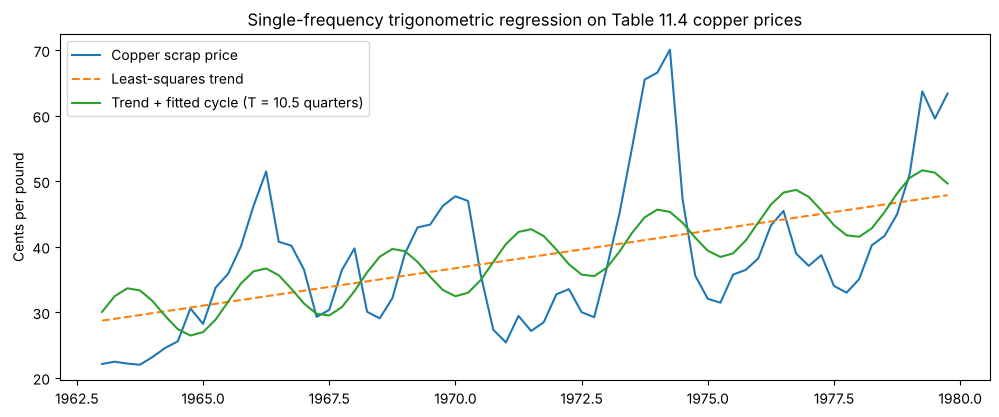

Share of detrended variance explained by the single cycle: 10.1%


In [6]:
f = single_frequency_fit(yq)
years = copper['year'] + (copper['quarter'] - 1) / 4

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(years, yq, label='Copper scrap price')
ax.plot(years, f['trend'], '--', label='Least-squares trend')
ax.plot(years, f['trend'] + f['fitted_cycle'], label=f"Trend + fitted cycle (T = {f['period']:.1f} quarters)")
ax.set(title='Single-frequency trigonometric regression on Table 11.4 copper prices',
       ylabel='Cents per pound')
ax.legend()
plt.show()
r2 = 1 - ((yq - f['trend'] - f['fitted_cycle'])**2).sum() / ((yq - f['trend'])**2).sum()
print(f'Share of detrended variance explained by the single cycle: {r2:.1%}')

## 5. Fourier analysis and the periodogram

The periodogram shows how much of the series' variance sits at each period. The spectral **power** is proportional to amplitude squared.

Rules from the book:
- remove the trend first, or it shows up as a giant "long cycle";
- the data must hold several full repetitions of any cycle you claim;
- Fourier analysis assumes the series is **stationary** (its structure does not change over time).

Recreate Figure 11.12: three pure waves of 10, 20 and 40 bars.

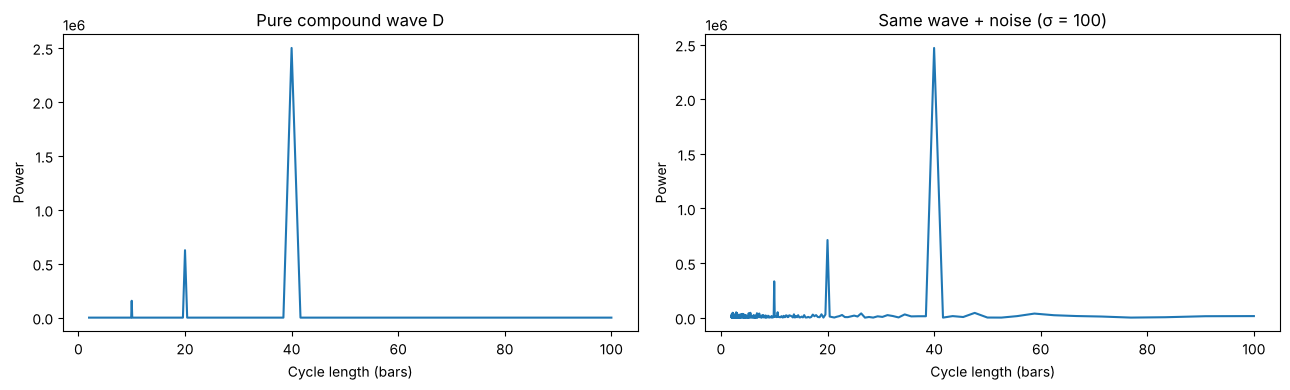

Strongest periods found in the clean wave: [10. 20. 40.]
Strongest periods with noise: [10. 20. 40.]


In [7]:
def periodogram(x):
    x = np.asarray(x, float)
    x = x - x.mean()
    n = len(x)
    power = np.abs(np.fft.rfft(x))**2 / n
    freq = np.fft.rfftfreq(n)            # cycles per bar
    keep = freq > 0
    return pd.Series(power[keep], index=1 / freq[keep], name='power').sort_index()

def top_periods(spec, k=3, min_period=2):
    s = spec[spec.index >= min_period]
    peaks = s[(s > s.shift(1, fill_value=0)) & (s > s.shift(-1, fill_value=0))]
    return peaks.nlargest(k).index.to_numpy()

t250 = np.arange(1000)
waves = {'A (10 bars)': 25 * np.sin(2 * np.pi * t250 / 10),
         'B (20 bars)': 50 * np.sin(2 * np.pi * t250 / 20),
         'C (40 bars)': 100 * np.sin(2 * np.pi * t250 / 40)}
D = sum(waves.values())
spec_clean = periodogram(D)
spec_noisy = periodogram(D + rng.normal(0, 100, len(D)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, spec, title in [(axes[0], spec_clean, 'Pure compound wave D'),
                        (axes[1], spec_noisy, 'Same wave + noise (σ = 100)')]:
    s = spec[spec.index <= 100]
    ax.plot(s.index, s.values)
    ax.set(title=title, xlabel='Cycle length (bars)', ylabel='Power')
plt.tight_layout()
plt.show()

found = np.sort(top_periods(spec_clean))
print('Strongest periods found in the clean wave:', found)
assert np.allclose(found, [10, 20, 40])
print('Strongest periods with noise:', np.sort(top_periods(spec_noisy)))

### Recovering the planted cycles from the synthetic price

Apply the periodogram to the **detrended** synthetic series from section 2. The planted periods were 40 and 20 bars.

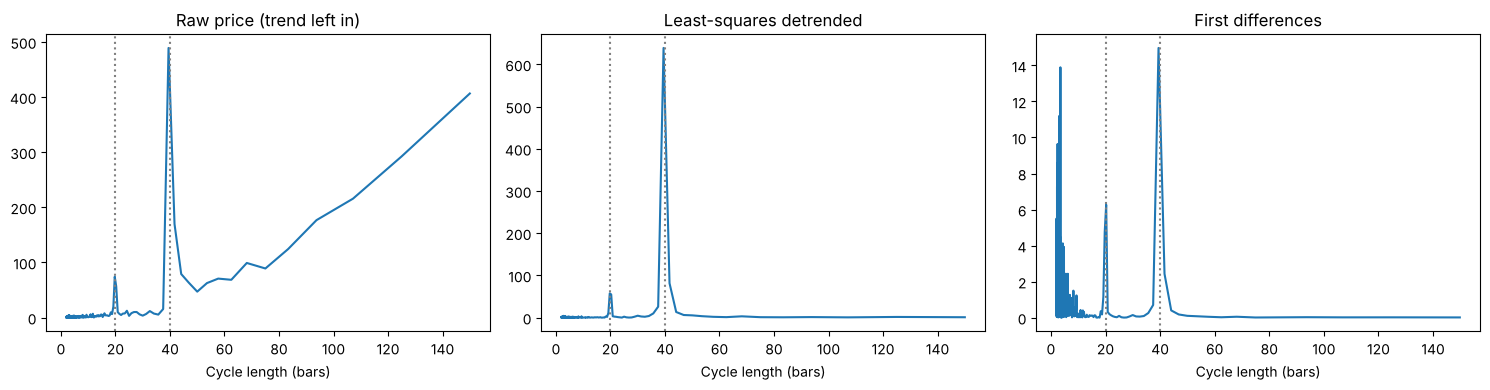

Top periods, raw price:      [750.   39.5  68.2] <- trend appears as a long "cycle"
Top periods, LS detrended:   [39.5 19.7 30. ]
Top periods, first diffs:    [39.4  3.5  3. ] <- differencing boosts short cycles and noise
Planted 20- and 40-bar cycles recovered to within one FFT bin.


In [8]:
first_diff = synthetic.diff().dropna()
spec_price = periodogram(synthetic)                                  # trend left in
spec_diff = periodogram(first_diff)                                  # first differences
spec_line = periodogram(synthetic - np.polyval(np.polyfit(t, synthetic, 1), t))  # least-squares detrend

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, spec, title in [(axes[0], spec_price, 'Raw price (trend left in)'),
                        (axes[1], spec_line, 'Least-squares detrended'),
                        (axes[2], spec_diff, 'First differences')]:
    s = spec[spec.index <= 150]
    ax.plot(s.index, s.values)
    for p in TRUE_PERIODS:
        ax.axvline(p, color='grey', linestyle=':')
    ax.set(title=title, xlabel='Cycle length (bars)')
plt.tight_layout()
plt.show()

print('Top periods, raw price:     ', np.round(top_periods(spec_price), 1), '<- trend appears as a long "cycle"')
print('Top periods, LS detrended:  ', np.round(top_periods(spec_line), 1))
print('Top periods, first diffs:   ', np.round(top_periods(spec_diff), 1), '<- differencing boosts short cycles and noise')
# FFT bins sit at n/k bars, so with n = 750 the nearest bins to 40 and 20 are 39.5 and 19.7.
# This is frequency resolution: periods are only measured to within a bin.
assert np.allclose(np.sort(top_periods(spec_line, 2)), sorted(TRUE_PERIODS), atol=1)
print('Planted 20- and 40-bar cycles recovered to within one FFT bin.')

### Pitfall in the book's Excel example (pp. 511–513)

The book runs Excel's Fourier analysis on monthly Southwest Airlines and corn returns, takes the first 12 output rows and labels them **Jan to Dec**.

That labelling is not correct. FFT output row `k` holds the cycle of length **N/k bars**, not calendar month `k`. With 128 monthly values:
- row 0 is the average (not a cycle);
- row 1 is a 128-month cycle, row 2 a 64-month cycle, …, row 11 an 11.6-month cycle.

None of those rows means "January". Seasonality would show up only near a period of **12 months**, which is row `N/12` (about row 10.7 for N = 128). The cell below shows this with a planted 12-month cycle.

In [9]:
N = 128
months = np.arange(N)
monthly = 1.0 * np.sin(2 * np.pi * months / 12) + rng.normal(0, 0.5, N)
mag = np.abs(np.fft.fft(monthly))
table = pd.DataFrame({'fft_row': np.arange(12),
                      'cycle_length_months': [np.inf] + [N / k for k in range(1, 12)],
                      'book_label': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
                      'IMABS': mag[:12]})
display(table.round(2))
peak_row = int(table.loc[1:, 'IMABS'].idxmax())
label = table.loc[peak_row, 'book_label']
print(f'The planted 12-month cycle peaks at FFT row {peak_row}, i.e. a period of {N / peak_row:.1f} months,')
print(f'which the book\'s labelling would call "{label}". It is one 12-month cycle, not a {label} effect.')

,fft_row,cycle_length_months,book_label,IMABS
0,0,inf,Jan,0.03
1,1,128.00,Feb,6.18
2,2,64.00,Mar,5.59
3,3,42.67,Apr,11.36
4,4,32.00,May,3.58
5,5,25.60,Jun,8.78
6,6,21.33,Jul,5.79
7,7,18.29,Aug,7.92
8,8,16.00,Sep,4.75
9,9,14.22,Oct,11.28


The planted 12-month cycle peaks at FFT row 11, i.e. a period of 11.6 months,
which the book's labelling would call "Dec". It is one 12-month cycle, not a Dec effect.


## 6. The most important failure mode: smoothing creates cycles

This is the **Slutsky–Yule effect**. Take a pure random walk, which has no cycles by construction. Apply a band-pass filter such as the triangular MACD. The output looks like a clean, regular cycle.

The "cycle" belongs to the **filter**, not the market. Any MA-difference indicator passes a band of periods and suppresses the rest, so it always shows waves in that band.

This is the cycle version of finding a "best month" in the seasonality study.

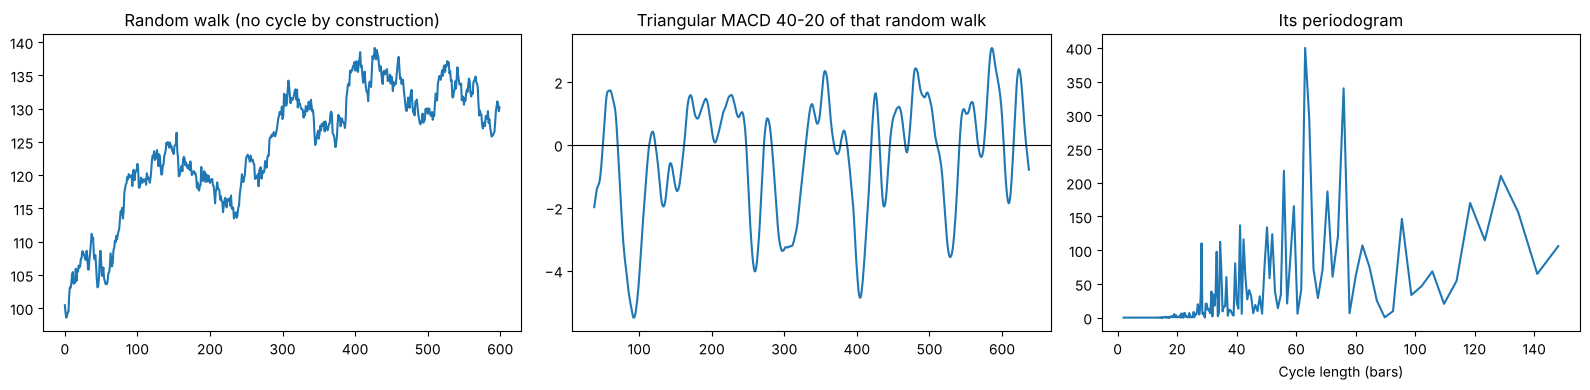

Peak-to-peak spacing of the "cycle": median 31 bars, interquartile range 23-39 bars.
Periodogram peak of the filtered noise: 63 bars.
The filter manufactured a regular-looking cycle from noise.


In [10]:
walk = pd.Series(100 + np.cumsum(rng.normal(0, 1, 3000)))
tmacd_walk = triangular_macd(walk, 40).dropna()

def turning_point_spacing(x):
    s = np.sign(np.diff(np.asarray(x)))
    peaks = np.flatnonzero((s[:-1] > 0) & (s[1:] <= 0)) + 1
    return np.diff(peaks)

spacing = turning_point_spacing(tmacd_walk)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(walk.iloc[:600]); axes[0].set_title('Random walk (no cycle by construction)')
axes[1].plot(tmacd_walk.iloc[:600]); axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Triangular MACD 40-20 of that random walk')
spec_walk = periodogram(tmacd_walk)
s = spec_walk[spec_walk.index <= 150]
axes[2].plot(s.index, s.values); axes[2].set(title='Its periodogram', xlabel='Cycle length (bars)')
plt.tight_layout()
plt.show()

print(f'Peak-to-peak spacing of the "cycle": median {np.median(spacing):.0f} bars, '
      f'interquartile range {np.percentile(spacing, 25):.0f}-{np.percentile(spacing, 75):.0f} bars.')
print(f'Periodogram peak of the filtered noise: {top_periods(spec_walk, 1)[0]:.0f} bars.')
print('The filter manufactured a regular-looking cycle from noise.')

### Defence: test against a null model

Never accept a periodogram peak because it is the tallest one. Decide in advance:
- **statistic:** the largest periodogram value over the periods you care about;
- **null:** the same series with its order destroyed (shuffled returns), which keeps the return distribution but removes any cycle;
- **decision:** the share of shuffled series with a peak at least as large is the p-value.

Because you look at many periods at once, this "maximum over all periods" test already accounts for multiple testing.

In [11]:
def max_peak_test(returns, min_period, max_period, n_perm=5000, seed=1101):
    rng_local = np.random.default_rng(seed)
    r = np.asarray(returns, float)
    def stat(x):
        spec = periodogram(x)
        band = spec[(spec.index >= min_period) & (spec.index <= max_period)]
        return band.max(), band.idxmax()
    observed, at_period = stat(r)
    null = np.array([stat(rng_local.permutation(r))[0] for _ in range(n_perm)])
    p = ((null >= observed).sum() + 1) / (n_perm + 1)
    return observed, at_period, p, null

# Sanity check 1: the synthetic series, which has real cycles, should be detected.
obs, per, p_synth, _ = max_peak_test(synthetic.diff().dropna(), 4, 120, n_perm=1000)
print(f'Synthetic (true cycles): strongest period {per:.1f} bars, p = {p_synth:.4f}')
# Sanity check 2: a random walk's returns should not be.
obs, per, p_walk, _ = max_peak_test(walk.diff().dropna().iloc[:750], 4, 120, n_perm=1000)
print(f'Random walk (no cycles): strongest period {per:.1f} bars, p = {p_walk:.3f}')
assert p_synth < 0.01

Synthetic (true cycles): strongest period 39.4 bars, p = 0.0020


Random walk (no cycles): strongest period 13.6 bars, p = 0.968


## 7. Is there a cycle in NIFTY monthly returns?

**Pre-declared before running:**
- **data:** NIFTY 50 monthly log returns from the repository, longest contiguous run without missing months (2002-02 to 2025-12);
- **H0:** returns contain no periodic structure (their order is exchangeable);
- **statistic:** largest periodogram value for periods of 3 to 60 months;
- **test:** 5,000 shuffles, seed 1101; reject at 5%;
- **no** other periods, windows or data choices will be tried after seeing the result.

Limitation: shuffling also destroys volatility clustering, so it is a fairly lenient null. Treat a rejection as "worth investigating", not as a tradable cycle.

287 monthly returns, 2002-02 to 2025-12


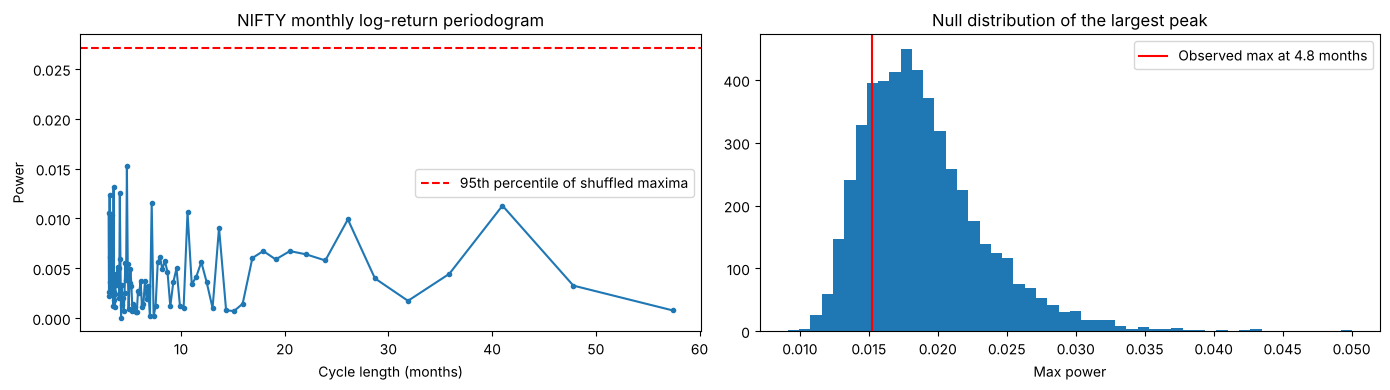

Largest peak: 4.8 months, permutation p = 0.804
Decision: do not reject H0: no evidence of a cycle in this test


In [12]:
nifty = pd.read_csv(REPO / '02_nifty_seasonality' / 'data' / 'nifty50_monthly_2000_2026_partial.csv',
                    parse_dates=['month']).set_index('month').sort_index()
nifty = nifty[(nifty.index >= '2002-01-01') & (nifty.index < '2026-01-01')]
code_month = nifty.index.year * 12 + nifty.index.month
assert (np.diff(code_month) == 1).all(), 'Window must be contiguous'
log_ret = np.log(nifty['close']).diff().dropna()
print(f'{len(log_ret)} monthly returns, {log_ret.index[0]:%Y-%m} to {log_ret.index[-1]:%Y-%m}')

obs, per, p_nifty, null = max_peak_test(log_ret, 3, 60, n_perm=5000, seed=1101)
spec_n = periodogram(log_ret)
band = spec_n[(spec_n.index >= 3) & (spec_n.index <= 60)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(band.index, band.values, marker='.')
axes[0].axhline(np.percentile(null, 95), color='red', linestyle='--', label='95th percentile of shuffled maxima')
axes[0].set(title='NIFTY monthly log-return periodogram', xlabel='Cycle length (months)', ylabel='Power')
axes[0].legend()
axes[1].hist(null, bins=50)
axes[1].axvline(obs, color='red', label=f'Observed max at {per:.1f} months')
axes[1].set(title='Null distribution of the largest peak', xlabel='Max power')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f'Largest peak: {per:.1f} months, permutation p = {p_nifty:.3f}')
print('Decision:', 'reject H0 (investigate further)' if p_nifty < 0.05 else 'do not reject H0: no evidence of a cycle in this test')

## 8. Hilbert transform: phase from a few bars (Ehlers)

Ehlers splits the cycle into two parts (p. 516):
- **InPhase:** `I = price_{t−3}`
- **Quadrature:** `Q = 0.0962·p_t + 0.5769·p_{t−2} − 0.5769·p_{t−4} − 0.0962·p_{t−6}`

Phase angle `θ` comes from the ratio of Q and I. Two details the book leaves out:
- **gain:** this short filter shrinks Q at longer periods (to about 0.51× at 20 bars). Ehlers multiplies Q by `0.075·Period + 0.54` to correct it, which needs an estimate of the period;
- **direction:** the book measures the angle clockwise like a clock hand. In standard maths orientation `atan2(Q, I)` runs backwards, so the code uses `atan2(I, Q)`, which rises.

For a clean cycle, θ rises steadily from 0° to 360° and resets, forming a **sawtooth** (Figure 11.18). When the sawtooth breaks down, the cycle has ended. Ehlers' rule: *if a short-term cycle exists, the market is not trending.*

The input must already be **detrended** and centred on zero. Here: pure sine, then the same sine with noise, then a random walk detrended by the triangular MACD. All three assume a 20-bar period for the gain correction.

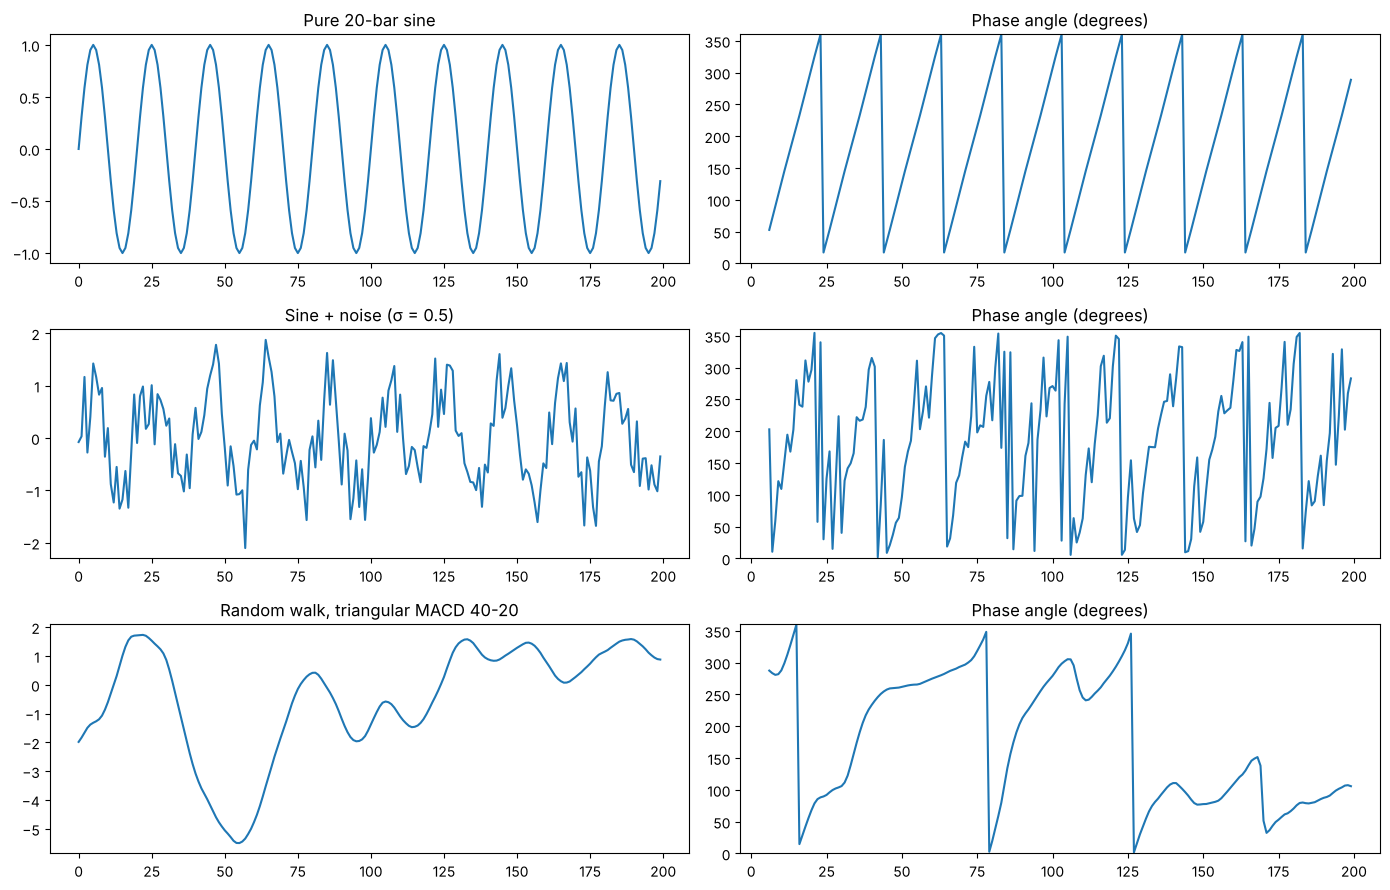

Pure sine: phase advances 18.0° per bar (ideal 360/20 = 18°).
Largest deviation from 18° on any bar: 0.8°


In [13]:
def hilbert_phase(x, period):
    x = pd.Series(x)
    gain_fix = 0.075 * period + 0.54                     # Ehlers' amplitude correction
    Q = (0.0962 * x + 0.5769 * x.shift(2) - 0.5769 * x.shift(4) - 0.0962 * x.shift(6)) * gain_fix
    I = x.shift(3)
    return np.degrees(np.arctan2(I, Q)) % 360

bars = np.arange(200)
sine = np.sin(2 * np.pi * bars / 20)
inputs = {'Pure 20-bar sine': sine,
          'Sine + noise (σ = 0.5)': sine + rng.normal(0, 0.5, len(bars)),
          'Random walk, triangular MACD 40-20': tmacd_walk.iloc[:200].to_numpy()}

fig, axes = plt.subplots(len(inputs), 2, figsize=(14, 9))
for row, (name, x) in zip(axes, inputs.items()):
    row[0].plot(x); row[0].set_title(name)
    row[1].plot(hilbert_phase(x, period=20)); row[1].set(title='Phase angle (degrees)', ylim=(0, 360))
plt.tight_layout()
plt.show()

ph = hilbert_phase(sine, period=20).dropna().to_numpy()
steps = np.diff(ph) % 360
print(f'Pure sine: phase advances {np.median(steps):.1f}° per bar (ideal 360/20 = 18°).')
assert abs(np.median(steps) - 18) < 1
print(f'Largest deviation from 18° on any bar: {np.abs(steps - 18).max():.1f}°')

Notice the third row: the filtered random walk also produces a convincing sawtooth for stretches. A clean phase does not prove a real cycle. It only shows that the input currently oscillates, which a filter can arrange by itself.

## 9. Fisher transform and inverse Fisher transform

A sine wave spends most of its time near its peaks and troughs, so its distribution is U-shaped, not bell-shaped (Figure 11.21). Price position within a channel behaves similarly.

**Fisher transform** (pp. 518–519):
1. `X_t = 0.5·2·((P_t − MinL)/(MaxH − MinL) − 0.5) + 0.5·X_{t−1}` over a `p`-bar channel;
2. clamp `X` inside (−1, 1);
3. `y = 0.5·ln((1 + X)/(1 − X))`.

**Inverse Fisher on RSI** (p. 520, book's TradeStation code): `series = close − close[mom]`, `x1 = 0.1·(RSI(series, RSIper) − 50)`, `x2 = WMA(x1, waper)`, `invfisher = 100·(e^{2·x2} − 1)/(e^{2·x2} + 1)`, with `mom = 10`, `RSIper = 20`, `waper = 30`.

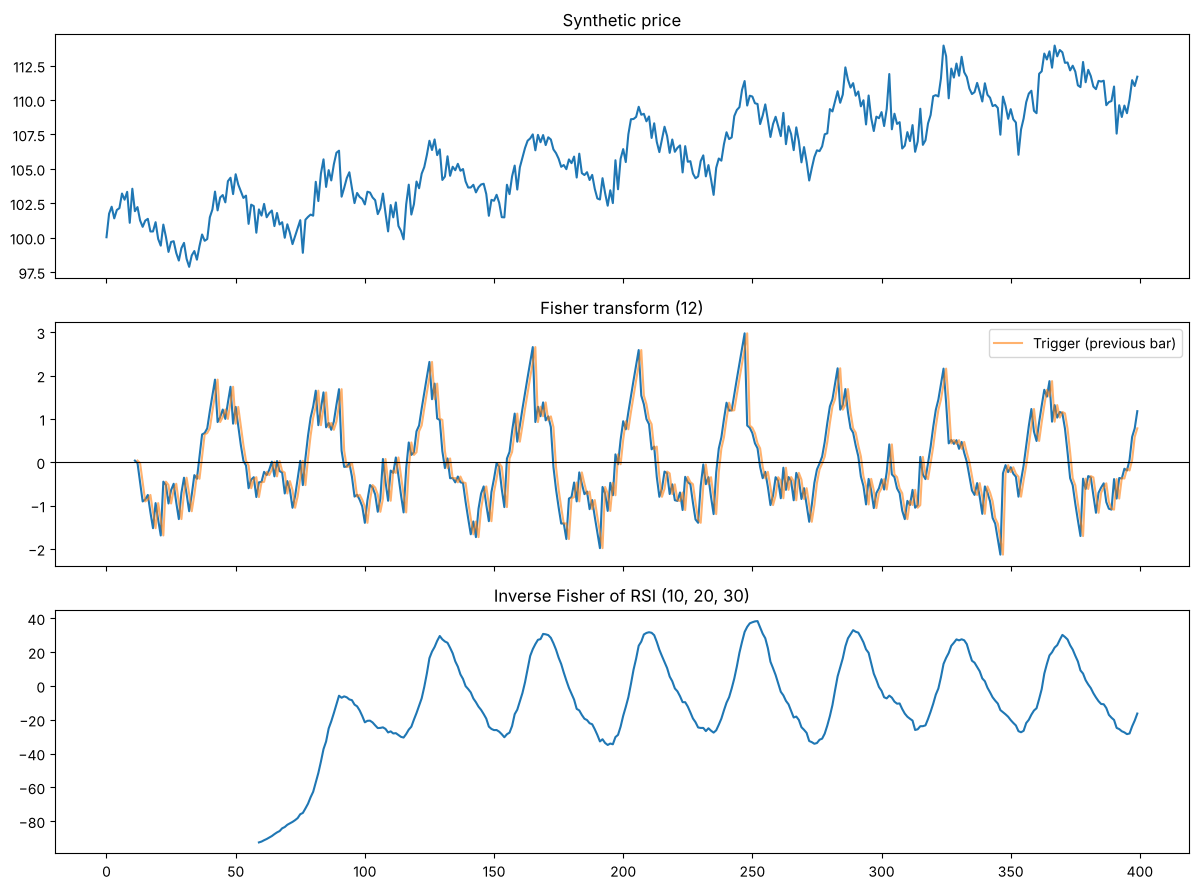

Channel position: 45% of bars in the outer 20% (U-shaped).


In [14]:
def fisher_transform(price, period=12):
    lo = price.rolling(period).min()
    hi = price.rolling(period).max()
    pos = ((price - lo) / (hi - lo).replace(0, np.nan) - 0.5).to_numpy()
    x = np.full(len(price), np.nan)
    prev = 0.0
    for i, v in enumerate(pos):
        if np.isnan(v):
            continue
        prev = np.clip(0.5 * 2 * v + 0.5 * prev, -0.999, 0.999)
        x[i] = prev
    return pd.Series(0.5 * np.log((1 + x) / (1 - x)), index=price.index)

def rsi_wilder(series, n=14):
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    avg_loss = loss.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    return (100 - 100 / (1 + rs)).fillna(100).where(avg_gain.notna())

def wma(series, n):
    w = np.arange(1, n + 1)
    return series.rolling(n).apply(lambda x: np.dot(x, w) / w.sum(), raw=True)

def inverse_fisher_rsi(close, mom=10, rsi_period=20, wma_period=30):
    x2 = wma(0.1 * (rsi_wilder(close - close.shift(mom), rsi_period) - 50), wma_period)
    return 100 * (np.exp(2 * x2) - 1) / (np.exp(2 * x2) + 1)

px = synthetic.iloc[:400]
fish = fisher_transform(px, 12)
inv = inverse_fisher_rsi(px)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(px); axes[0].set_title('Synthetic price')
axes[1].plot(fish); axes[1].plot(fish.shift(1), alpha=0.6, label='Trigger (previous bar)')
axes[1].axhline(0, color='black', linewidth=0.8); axes[1].set_title('Fisher transform (12)'); axes[1].legend()
axes[2].plot(inv); axes[2].set_title('Inverse Fisher of RSI (10, 20, 30)')
plt.tight_layout()
plt.show()

raw_pos = ((px - px.rolling(12).min()) / (px.rolling(12).max() - px.rolling(12).min())).dropna()
print(f'Channel position: {((raw_pos < 0.1) | (raw_pos > 0.9)).mean():.0%} of bars in the outer 20% (U-shaped).')
assert inv.dropna().between(-100, 100).all()

## 10. Commodity Channel Index (Lambert)

`x_t = (H_t + L_t + C_t)/3`, `CCI_t = (x_t − x̄_t) / (0.015 · MD_t)`

- `x̄_t` = **average** of `x` over the last `N` bars;
- `MD_t` = **average** absolute deviation of `x` from `x̄_t` over the last `N` bars;
- `N` should be **less than ¼ of the cycle**.

**Book typo:** p. 521 prints `x̄_t` as a plain sum. It must be the average, or the CCI is meaningless. The `N` that the book says "has been omitted" cancels only in the ratio of the two averages.

Rule: above +100 is a cyclic turn up; below −100 is a cyclic turn down. The 0.015 constant is meant to keep 70–80% of values inside ±100.

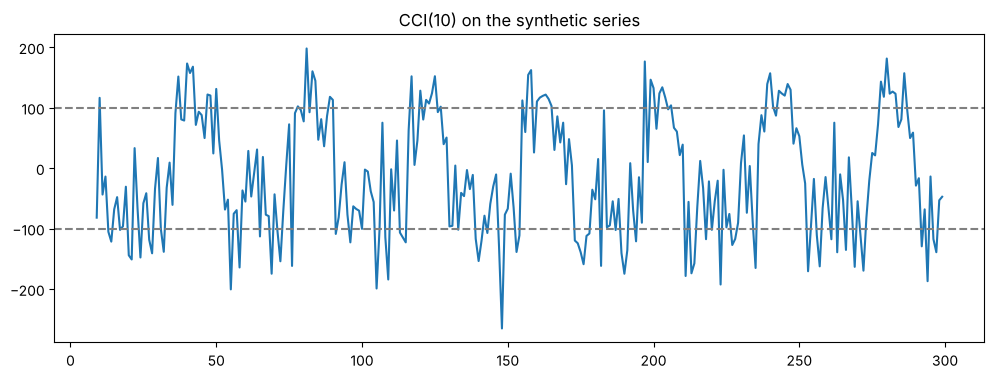

Share of CCI values inside ±100: 60% (book: 70-80%)
The share depends on the data: a strong, regular cycle pushes more values past ±100 than typical prices do.


In [15]:
def cci(high, low, close, n):
    x = (high + low + close) / 3
    mean = x.rolling(n).mean()
    md = x.rolling(n).apply(lambda w: np.abs(w - w.mean()).mean(), raw=True)
    return (x - mean) / (0.015 * md)

spread = np.abs(rng.normal(0.6, 0.2, len(synthetic)))
hi_s, lo_s = synthetic + spread, synthetic - spread
cci10 = cci(hi_s, lo_s, synthetic, 10)            # N = 10 = 1/4 of the 40-bar cycle

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cci10.iloc[:300])
for lvl in (100, -100):
    ax.axhline(lvl, color='grey', linestyle='--')
ax.set_title('CCI(10) on the synthetic series')
plt.show()
print(f'Share of CCI values inside ±100: {cci10.dropna().between(-100, 100).mean():.0%} (book: 70-80%)')
print('The share depends on the data: a strong, regular cycle pushes more values past ±100 than typical prices do.')

## 11. Hurst's phasing: why it looks ahead

Hurst (pp. 523–526) centres a full-span and a half-span moving average by plotting each one **half its length back in time**. The phased average then lies on top of the price swings, and its crossings are used to project a trend and price targets.

The catch: a moving average plotted `F/2` bars back has **no value for the last `F/2` bars**. Everything after that point is projection. When you test this method, use only the value that was available on each day; otherwise the backtest knows the future.

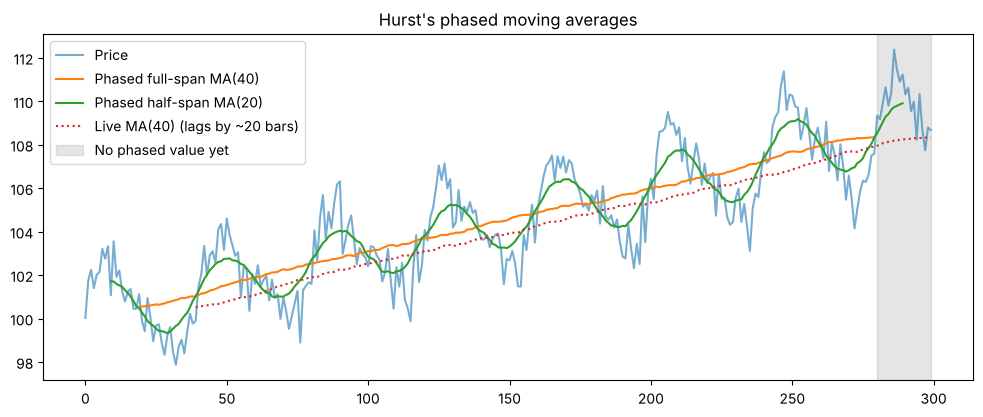

Last 20 bars have no phased full-span value.


In [16]:
F, H = 40, 20
px = synthetic.iloc[:300]
full_centred = px.rolling(F).mean().shift(-F // 2)   # value plotted F/2 bars back
half_centred = px.rolling(H).mean().shift(-H // 2)
full_live = px.rolling(F).mean()                    # what you actually know on each day

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(px, alpha=0.6, label='Price')
ax.plot(full_centred, label=f'Phased full-span MA({F})')
ax.plot(half_centred, label=f'Phased half-span MA({H})')
ax.plot(full_live, ':', label=f'Live MA({F}) (lags by ~{F // 2} bars)')
ax.axvspan(len(px) - F // 2, len(px) - 1, color='grey', alpha=0.2, label='No phased value yet')
ax.legend()
ax.set_title("Hurst's phased moving averages")
plt.show()

print(f'Last {full_centred.isna()[::-1].cumprod().sum()} bars have no phased full-span value.')
assert full_centred.iloc[-F // 2:].isna().all()

## 12. What is missing before any of this becomes a strategy?

- a cycle that survives a pre-declared null test **out of sample**;
- evidence that the cycle period is stable enough to trade (the book's Swiss franc example shows it is often not);
- exact entry, exit and stop rules, and execution timing;
- costs, slippage and position sizing;
- a check that the indicator adds information beyond the momentum indicators from Chapter 9 (the book itself notes the triangular MACD and Hilbert output behave like momentum).

Not implemented here: **MESA** (Burg maximum-entropy method; needs Ehlers' full algorithm) and the **Short Cycle Indicator** (p. 522 uses a term `C` that the book never defines).

In [17]:
assert np.allclose(triangular_weights(10).sum(), 10)
assert np.allclose(np.sort(top_periods(spec_line, 2)), sorted(TRUE_PERIODS), atol=1)
assert full_centred.iloc[-F // 2:].isna().all()
print('Chapter 11 sanity checks passed.')

Chapter 11 sanity checks passed.


## Reflection — answer before Chapter 12

1. What are amplitude, period, frequency and phase?
2. Why must the trend be removed before looking for a cycle, and what does a trend look like in a periodogram?
3. Why does a 40-bar difference hide a 40-bar cycle?
4. Why could the copper cycle period not be reproduced, and what does that say about single-frequency fits?
5. Why does the book's Jan–Dec label on Fourier output not mean months of the year?
6. How can a triangular MACD show a regular cycle in a random walk?
7. What null hypothesis did the NIFTY test use, and what are its limits?
8. What does a breakdown in the Hilbert phase sawtooth tell Ehlers?
9. Why can Hurst's phased averages not be used as-is in a backtest?

**Do not optimise any parameters yet.**